In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from google.colab import files

# **Load Results Dataset**

In [18]:
training_results1 = pd.read_excel("/content/drive/MyDrive/DeepFake Detection Project/Results/1PI_TDCNN_ConvLSTM/Train_Metrics.xlsx")
validation_results1 = pd.read_excel("/content/drive/MyDrive/DeepFake Detection Project/Results/1PI_TDCNN_ConvLSTM/Validation_Metrics.xlsx")

In [19]:
training_results2 = pd.read_excel("/content/drive/MyDrive/DeepFake Detection Project/Results/2PI_TDCNN_ConvLSTM/Train_Metrics.xlsx")
validation_results2 = pd.read_excel("/content/drive/MyDrive/DeepFake Detection Project/Results/2PI_TDCNN_ConvLSTM/Validation_Metrics.xlsx")

In [20]:
training_results3 = pd.read_excel("/content/drive/MyDrive/DeepFake Detection Project/Results/3PI_TDCNN_ConvLSTM/Train_Metrics.xlsx")
validation_results3 = pd.read_excel("/content/drive/MyDrive/DeepFake Detection Project/Results/3PI_TDCNN_ConvLSTM/Validation_Metrics.xlsx")

In [7]:
training_results1

,Loss,Accuracy,AUC,Precision,Recall
0,0.692746,0.561905,0.559402,0.409649,0.385170
1,0.609074,0.671429,0.741304,0.607755,0.650703
2,0.571014,0.713095,0.760624,0.642766,0.735782
3,0.552382,0.728571,0.791154,0.659218,0.733401
4,0.544590,0.713095,0.797174,0.647154,0.729751
5,0.569876,0.717857,0.778540,0.628141,0.732698
6,0.516276,0.753571,0.840037,0.715624,0.776576
7,0.508755,0.748810,0.830655,0.712721,0.755283
8,0.478759,0.772619,0.863818,0.735896,0.782925
9,0.462524,0.786905,0.869756,0.744512,0.793243


In [21]:
training_results2, validation_results2

(        Loss  Accuracy       AUC  Precision    Recall
 0   0.704892  0.538095  0.467409   0.268197  0.194444
 1   0.675728  0.578571  0.581874   0.467347  0.380499
 2   0.613283  0.661905  0.745564   0.607664  0.661134
 3   0.583721  0.702381  0.764382   0.642721  0.701882
 4   0.584519  0.689286  0.771329   0.644138  0.742494
 5   0.569478  0.707143  0.777120   0.676395  0.729388
 6   0.566683  0.708333  0.777463   0.664059  0.764898
 7   0.562027  0.708333  0.786618   0.673073  0.755374
 8   0.547270  0.730952  0.789773   0.701905  0.707982
 9   0.554296  0.721429  0.791148   0.688095  0.775351
 10  0.539443  0.734524  0.787868   0.701202  0.755601
 11  0.533295  0.739286  0.810745   0.697347  0.788005
 12  0.528028  0.746429  0.820445   0.704150  0.772109
 13  0.523040  0.739286  0.822687   0.707585  0.756145
 14  0.525085  0.727381  0.818554   0.700181  0.758526
 15  0.517247  0.753571  0.830125   0.706429  0.791406
 16  0.507916  0.755952  0.844164   0.692721  0.782358
 17  0.497

In [9]:
training_results3

,Loss,Accuracy,Precision,Recall,AUC
0,0.692047,0.544048,0.418639,0.421383,0.543781
1,0.659248,0.634524,0.516463,0.531224,0.680745
2,0.591742,0.700000,0.629059,0.667256,0.750581
3,0.570273,0.729762,0.669229,0.731565,0.779753
4,0.560522,0.717857,0.679365,0.722812,0.781664
5,0.559698,0.711905,0.648946,0.739161,0.794926
6,0.554056,0.725000,0.673107,0.759796,0.798492
7,0.540688,0.740476,0.686213,0.759569,0.796618
8,0.534994,0.728571,0.696213,0.745760,0.813835
9,0.530627,0.739286,0.696961,0.772109,0.824697


In [10]:
def calc_f1(precision,recall):
    f1 = 2*(precision*recall)/(precision+recall)
    return f1

In [26]:
training_f1 = list()
for i in range(0, len(training_results1)):
    training_f1.append(calc_f1(training_results1.loc[i,"Precision"],training_results1.loc[i,"Recall"]))
training_results1["F1 Score"] = training_f1
training_results1

,Loss,Accuracy,AUC,Precision,Recall,F1 Score
0,0.692746,0.561905,0.559402,0.409649,0.385170,0.397032
1,0.609074,0.671429,0.741304,0.607755,0.650703,0.628496
2,0.571014,0.713095,0.760624,0.642766,0.735782,0.686136
3,0.552382,0.728571,0.791154,0.659218,0.733401,0.694334
4,0.544590,0.713095,0.797174,0.647154,0.729751,0.685975
5,0.569876,0.717857,0.778540,0.628141,0.732698,0.676403
6,0.516276,0.753571,0.840037,0.715624,0.776576,0.744855
7,0.508755,0.748810,0.830655,0.712721,0.755283,0.733385
8,0.478759,0.772619,0.863818,0.735896,0.782925,0.758682
9,0.462524,0.786905,0.869756,0.744512,0.793243,0.768105


In [27]:
validation_f1 = list()
for i in range(0, len(validation_results1)):
    validation_f1.append(calc_f1(validation_results1.loc[i,"Precision"],validation_results1.loc[i,"Recall"]))
validation_results1["F1 Score"] = validation_f1

In [28]:
training_f1 = list()
for i in range(0, len(training_results2)):
    training_f1.append(calc_f1(training_results2.loc[i,"Precision"],training_results2.loc[i,"Recall"]))
training_results2["F1 Score"] = training_f1

In [29]:
validation_f1 = list()
for i in range(0, len(validation_results2)):
    validation_f1.append(calc_f1(validation_results2.loc[i,"Precision"],validation_results2.loc[i,"Recall"]))
validation_results2["F1 Score"] = validation_f1

/tmp/ipython-input-10-1071644077.py:2: RuntimeWarning: invalid value encountered in scalar divide
  f1 = 2*(precision*recall)/(precision+recall)


In [30]:
training_f1 = list()
for i in range(0, len(training_results3)):
    training_f1.append(calc_f1(training_results3.loc[i,"Precision"],training_results3.loc[i,"Recall"]))
training_results3["F1 Score"] = training_f1

In [31]:
validation_f1 = list()
for i in range(0, len(validation_results3)):
    validation_f1.append(calc_f1(validation_results3.loc[i,"Precision"],validation_results3.loc[i,"Recall"]))
validation_results3["F1 Score"] = validation_f1

In [32]:
presentable_metrics1 = pd.DataFrame()
presentable_metrics1["Training Accuracy"] = training_results1["Accuracy"]
presentable_metrics1["Validation Accuracy"] = validation_results1["Accuracy"]
presentable_metrics1["Training Precision"] = training_results1["Precision"]
presentable_metrics1["Validation Precision"] = validation_results1["Precision"]
presentable_metrics1["Training Recall"] = training_results1["Recall"]
presentable_metrics1["Validation Recall"] = validation_results1["Recall"]
presentable_metrics1["Training F1 Score"] = training_results1["F1 Score"]
presentable_metrics1["Validation F1 Score"] = validation_results1["F1 Score"]
presentable_metrics1["Training Loss"] = training_results1["Loss"]
presentable_metrics1["Validation Loss"] = validation_results1["Loss"]
presentable_metrics1

,Training Accuracy,Validation Accuracy,Training Precision,Validation Precision,Training Recall,Validation Recall,Training F1 Score,Validation F1 Score,Training Loss,Validation Loss
0,0.561905,0.586538,0.409649,0.461538,0.385170,0.119231,0.397032,0.189506,0.692746,0.632413
1,0.671429,0.769231,0.607755,0.689560,0.650703,0.779487,0.628496,0.731771,0.609074,0.509477
2,0.713095,0.807692,0.642766,0.781868,0.735782,0.792308,0.686136,0.787053,0.571014,0.482657
3,0.728571,0.798077,0.659218,0.778022,0.733401,0.748718,0.694334,0.763089,0.552382,0.469047
4,0.713095,0.817308,0.647154,0.787179,0.729751,0.783333,0.685975,0.785252,0.544590,0.482935
5,0.717857,0.826923,0.628141,0.745971,0.732698,0.897436,0.676403,0.814723,0.569876,0.465836
6,0.753571,0.759615,0.715624,0.701099,0.776576,0.923077,0.744855,0.796919,0.516276,0.486940
7,0.748810,0.711538,0.712721,0.628663,0.755283,0.923077,0.733385,0.747940,0.508755,0.517855
8,0.772619,0.730769,0.735896,0.638095,0.782925,0.923077,0.758682,0.754575,0.478759,0.527336
9,0.786905,0.740385,0.744512,0.661172,0.793243,0.903846,0.768105,0.763694,0.462524,0.505224


In [40]:
presentable_metrics2 = pd.DataFrame()
presentable_metrics2["Training Accuracy"] = training_results2["Accuracy"]
presentable_metrics2["Validation Accuracy"] = validation_results2["Accuracy"]
presentable_metrics2["Training Precision"] = training_results2["Precision"]
presentable_metrics2["Validation Precision"] = validation_results2["Precision"]
presentable_metrics2["Training Recall"] = training_results2["Recall"]
presentable_metrics2["Validation Recall"] = validation_results2["Recall"]
presentable_metrics2["Training F1 Score"] = training_results2["F1 Score"]
presentable_metrics2["Validation F1 Score"] = validation_results2["F1 Score"]
presentable_metrics2["Training Loss"] = training_results2["Loss"]
presentable_metrics2["Validation Loss"] = validation_results2["Loss"]
presentable_metrics2 = presentable_metrics2.drop(index=0)
presentable_metrics2 = presentable_metrics2.reset_index(drop=True)
presentable_metrics2 = presentable_metrics2[0:13]
presentable_metrics2

,Training Accuracy,Validation Accuracy,Training Precision,Validation Precision,Training Recall,Validation Recall,Training F1 Score,Validation F1 Score,Training Loss,Validation Loss
0,0.578571,0.750000,0.467347,0.728205,0.380499,0.470513,0.419475,0.571661,0.675728,0.598843
1,0.661905,0.788462,0.607664,0.756410,0.661134,0.558974,0.633272,0.642875,0.613283,0.524558
2,0.702381,0.798077,0.642721,0.756410,0.701882,0.574359,0.671000,0.652932,0.583721,0.497225
3,0.689286,0.788462,0.644138,0.756410,0.742494,0.558974,0.689828,0.642875,0.584519,0.489799
4,0.707143,0.778846,0.676395,0.756410,0.729388,0.558974,0.701892,0.642875,0.569478,0.489176
5,0.708333,0.788462,0.664059,0.794872,0.764898,0.558974,0.710920,0.656371,0.566683,0.507444
6,0.708333,0.817308,0.673073,0.734615,0.755374,0.682051,0.711852,0.707358,0.562027,0.473220
7,0.730952,0.798077,0.701905,0.752381,0.707982,0.752564,0.704930,0.752473,0.547270,0.450446
8,0.721429,0.807692,0.688095,0.763919,0.775351,0.752564,0.729122,0.758199,0.554296,0.449130
9,0.734524,0.826923,0.701202,0.773077,0.755601,0.752564,0.727386,0.762683,0.539443,0.446272


In [36]:
presentable_metrics3 = pd.DataFrame()
presentable_metrics3["Training Accuracy"] = training_results3["Accuracy"]
presentable_metrics3["Validation Accuracy"] = validation_results3["Accuracy"]
presentable_metrics3["Training Precision"] = training_results3["Precision"]
presentable_metrics3["Validation Precision"] = validation_results3["Precision"]
presentable_metrics3["Training Recall"] = training_results3["Recall"]
presentable_metrics3["Validation Recall"] = validation_results3["Recall"]
presentable_metrics3["Training F1 Score"] = training_results3["F1 Score"]
presentable_metrics3["Validation F1 Score"] = validation_results3["F1 Score"]
presentable_metrics3["Training Loss"] = training_results3["Loss"]
presentable_metrics3["Validation Loss"] = validation_results3["Loss"]
presentable_metrics3

,Training Accuracy,Validation Accuracy,Training Precision,Validation Precision,Training Recall,Validation Recall,Training F1 Score,Validation F1 Score,Training Loss,Validation Loss
0,0.544048,0.538462,0.418639,0.307692,0.421383,0.097436,0.420007,0.148004,0.692047,0.660870
1,0.634524,0.817308,0.516463,0.860256,0.531224,0.775641,0.523740,0.815760,0.659248,0.509805
2,0.700000,0.769231,0.629059,0.879487,0.667256,0.646154,0.647595,0.744977,0.591742,0.478312
3,0.729762,0.826923,0.669229,0.823077,0.731565,0.810256,0.699010,0.816616,0.570273,0.402417
4,0.717857,0.855769,0.679365,0.819048,0.722812,0.879487,0.700415,0.848192,0.560522,0.394882
5,0.711905,0.846154,0.648946,0.819048,0.739161,0.864103,0.691122,0.840972,0.559698,0.407206
6,0.725000,0.807692,0.673107,0.806227,0.759796,0.797436,0.713829,0.801807,0.554056,0.406335
7,0.740476,0.826923,0.686213,0.828205,0.759569,0.767949,0.721030,0.796940,0.540688,0.410729
8,0.728571,0.826923,0.696213,0.828205,0.745760,0.767949,0.720135,0.796940,0.534994,0.408398
9,0.739286,0.836538,0.696961,0.776923,0.772109,0.853846,0.732613,0.813570,0.530627,0.399666


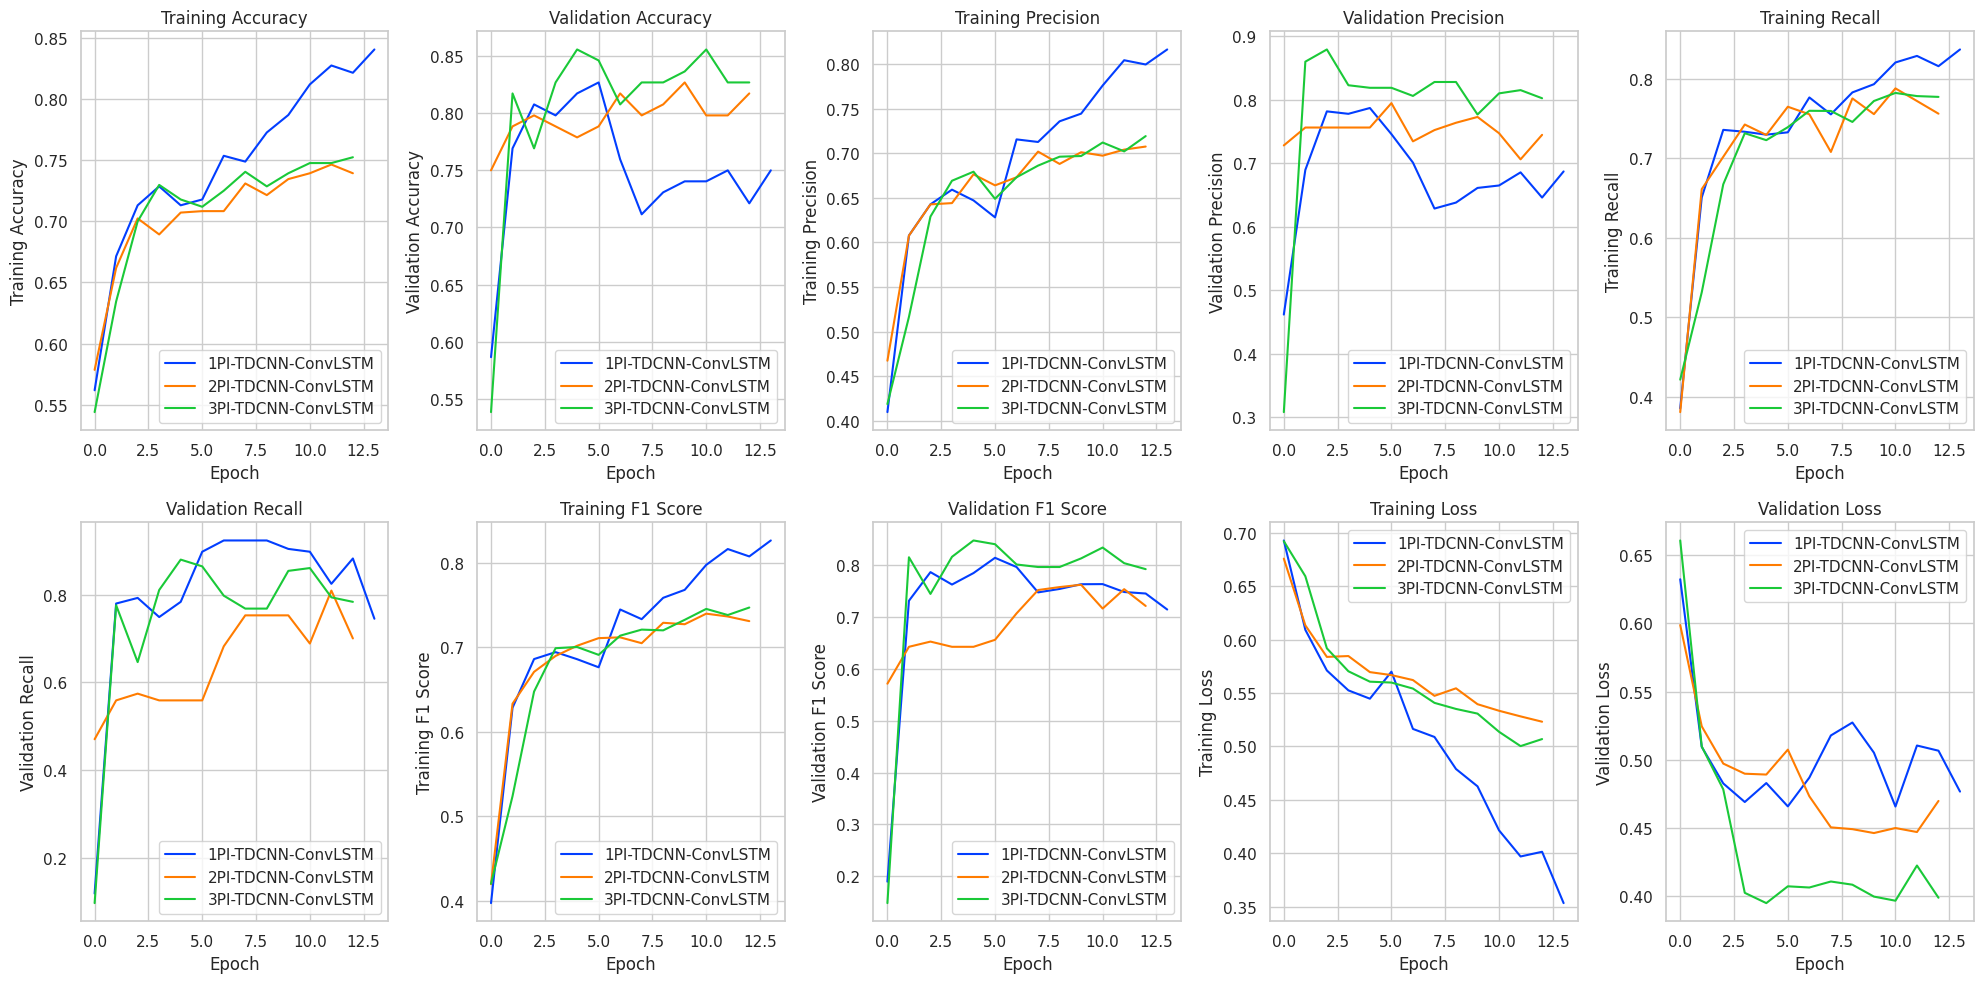

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
sns.set_theme(style="whitegrid")
sns.set_palette("bright")

axes = axes.flatten()
for i, column in enumerate(presentable_metrics1.columns):
    sns.lineplot(data=presentable_metrics1, x=presentable_metrics1.index, y=column, ax=axes[i], label="1PI-TDCNN-ConvLSTM")
    sns.lineplot(data=presentable_metrics2, x=presentable_metrics2.index, y=column, ax=axes[i], label="2PI-TDCNN-ConvLSTM")
    sns.lineplot(data=presentable_metrics3, x=presentable_metrics3.index, y=column, ax=axes[i], label="3PI-TDCNN-ConvLSTM")
    axes[i].set_title(column)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel(column)

plt.tight_layout()
plt.show()